# Policy Brief Analysis: Integrated Report

This notebook consolidates the exploratory and results reports into one source-aware analysis. It preserves the full analytical structure while removing duplicated sections and clarifying what each analysis uses and compares.

## How to read the report

- **Complete-brief analyses** use text extracted from the full policy brief.
- **Human-identified recommendation passages (LLM-assisted field extraction)** are passages selected by human coders as recommendations or solutions; an LLM then structures fields such as actor, instrument, expected outcome, and implementation guidance from those passages. The LLM does not select the passages.
- **LLM-identified recommendation passages** are recommendation or policy-option passages first identified by the LLM from complete briefs and then analysed at passage level.
- Source comparisons assess differences between extraction routes, not differences between documents.
- Code cells are hidden by default but retained for reproducibility.


In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=FutureWarning)

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

C_PRIMARY   = '#2F6B7C'
C_SECONDARY = '#3AAFA9'
C_ACCENT    = '#F4A261'
C_WARM      = '#E76F51'
C_AGREE     = '#4DB6AC'
C_DISAGREE  = '#EF9A9A'

OUTPUT_DIR   = Path.cwd() / 'output'
CROSSVAL_DIR = OUTPUT_DIR / 'crossval'
RECOMMENDATION_ANALYSIS_TYPES = {'recommendation', 'policy_option'}

def _load(name):
    p = OUTPUT_DIR / name
    if not p.exists():
        print(f'warning: {name} not found')
        return pd.DataFrame()
    return pd.read_csv(p)

def _col(df, col, default=None):
    return df[col] if col in df.columns else pd.Series(default, index=df.index, name=col)

def _has_col(df, col):
    return col in df.columns

documents       = _load('documents.csv')
frames          = _load('frames.csv')
recommendations = _load('recommendations.csv')
structural_core = _load('structural_core.csv')
recommendation_content = (
    recommendations[recommendations['extraction_type'].isin(RECOMMENDATION_ANALYSIS_TYPES)].copy()
    if 'extraction_type' in recommendations.columns else pd.DataFrame()
)

_cv  = CROSSVAL_DIR / 'metrics.json'
_cmp = CROSSVAL_DIR / 'comparison.csv'
crossval_metrics = json.loads(_cv.read_text())  if _cv.exists()  else {}
comparison_df    = pd.read_csv(_cmp)             if _cmp.exists() else pd.DataFrame()

# ── Build document-level analysis_df ─────────────────────────────────
analysis_df = documents[['doc_id']].copy()
analysis_df['A1_page_count'] = documents['page_count']

sc = structural_core.set_index('doc_id') if len(structural_core) else pd.DataFrame()
if len(sc):
    analysis_df['B2_problem_identified']    = analysis_df['doc_id'].map(sc['problem_status']).fillna('absent')
    # B3: support new three-level (solutions_status) and legacy boolean (solutions_explicit)
    if 'solutions_status' in sc.columns:
        analysis_df['B3_solutions_status'] = analysis_df['doc_id'].map(sc['solutions_status']).fillna('absent')
    elif 'solutions_explicit' in sc.columns:
        _bool_map = {True: 'present', False: 'absent', 'True': 'present', 'False': 'absent'}
        analysis_df['B3_solutions_status'] = analysis_df['doc_id'].map(
            sc['solutions_explicit'].map(_bool_map)
        ).fillna('absent')
    analysis_df['B3_solutions_count']       = analysis_df['doc_id'].map(sc['solutions_count']).fillna(0).astype(int)
    analysis_df['B4_implementation_status'] = analysis_df['doc_id'].map(sc['implementation_status']).fillna('absent')

if len(sc) and 'procedural_clarity_status' in sc.columns:
    analysis_df['C5_procedural_clarity'] = analysis_df['doc_id'].map(sc['procedural_clarity_status']).fillna('absent')
elif 'B4_implementation_status' in analysis_df.columns:
    analysis_df['C5_procedural_clarity'] = analysis_df['B4_implementation_status']

if len(recommendation_content):
    has_actor = recommendation_content.dropna(subset=['actor_raw']).groupby('doc_id').size().gt(0)
    analysis_df['C6_responsibility'] = analysis_df['doc_id'].map(has_actor).fillna(False)

if len(recommendations):
    has_outcome    = recommendations[recommendations['extraction_type'] == 'expected_outcome'].groupby('doc_id').size().gt(0)
    analysis_df['C7_anticipated_outcomes'] = analysis_df['doc_id'].map(has_outcome).fillna(False)
    analysis_df['D8_impacts_proxy']        = analysis_df['C7_anticipated_outcomes']
    has_tradeoff   = recommendations[recommendations['extraction_type'] == 'trade_off'].groupby('doc_id').size().gt(0)
    analysis_df['D9_tradeoffs']            = analysis_df['doc_id'].map(has_tradeoff).fillna(False)
    has_policy_opt = recommendation_content[recommendation_content['extraction_type'] == 'policy_option'].groupby('doc_id').size().gt(0)
    analysis_df['D10_policy_options']      = analysis_df['doc_id'].map(has_policy_opt).fillna(False)

if _has_col(documents, 'passive_voice_share'):
    analysis_df['E11_passive_voice_share'] = documents['passive_voice_share']
analysis_df['E12_avg_sentence_length']  = documents['avg_sentence_length']
analysis_df['E13_lexical_diversity']    = documents['lexical_diversity']
analysis_df['E14_flesch_reading_ease']  = _col(documents, 'flesch_reading_ease',  np.nan)
analysis_df['E14_flesch_kincaid_grade'] = _col(documents, 'flesch_kincaid_grade', np.nan)

if len(sc):
    analysis_df['F15_narrative_hook'] = analysis_df['doc_id'].map(sc['narrative_hook_present']).fillna(False)
    analysis_df['F15_hook_type']      = analysis_df['doc_id'].map(sc['narrative_hook_type'])

analysis_df['G16_funding'] = (
    documents['funding_statement_present']
    if _has_col(documents, 'funding_statement_present')
    else np.nan
)
analysis_df['G18_contact_info'] = (
    documents['fm_emails'].notna() | documents['fm_urls'].notna() | documents['fm_authors'].notna()
)

if len(frames):
    _pf = frames[frames['decision'] == 'present']
    _fp = _pf.assign(v=1).pivot_table(index='doc_id', columns='frame_label', values='v', fill_value=0)
    for _fc in _fp.columns:
        _safe = _fc.replace(' ', '_').replace('-', '_')
        analysis_df[f'H_{_safe}'] = analysis_df['doc_id'].map(_fp[_fc]).fillna(0).astype(int)
    analysis_df['H_frames_present_count'] = (
        analysis_df['doc_id'].map(_pf.groupby('doc_id').size()).fillna(0).astype(int)
    )

analysis_df['H24_policy_mix'] = _col(documents, 'policy_mix_present', False)

print(f'Corpus: {len(analysis_df)} documents, {analysis_df.shape[1] - 1} framework indicators ready')

Corpus: 154 documents, 27 framework indicators ready


## 1. Corpus and Methods[](#1.-Corpus-Description)

The corpus consists of policy briefs from European forest and biodiversity research projects processed by the automated extraction pipeline. Table 1 reports the number of extraction records per output file; Figure 1 shows the distribution of document length (pages and words), which reflects the scope of content available for analysis.

### Data sources and analysis passes

| Analysis route | Source unit | Purpose |
|---|---|---|
| Complete-brief document analysis | Full extracted policy-brief text | Document metadata, structure, readability, narrative, transparency, and document-level instrument frames |
| Full-brief policy extraction | Full extracted policy-brief text | Identify recommendation and policy-option passages and retain supporting evidence |
| LLM-identified passage analysis | Approved LLM-identified recommendation and policy-option passages | Structure recommendation-level actors, instruments, implementation guidance, expected outcomes, and related fields |
| Human-identified passage analysis | Passages manually coded as recommendations or solutions | Apply the same structured field extraction to a human-selected passage set |
| Source comparison | Outputs from the two passage-selection routes | Compare coverage and detected dimensions by extraction source; this is not a comparison of documents |
| Context comparison | Full-brief extraction versus passage-level reanalysis of the same LLM-identified items | Assess whether field detection changes when the model receives focused passage context |


**Table 1 — Extraction pipeline output sizes**

,Rows,Unique documents
Output file,,
documents.csv,154,154
structural_core.csv,154,154
recommendations.csv,1038,153
frames.csv,770,154


**Table 2 — Document length summary statistics**

,mean,median,std,min,max
Pages,26.2,11.0,37.8,2.0,187.0
Words,8736.8,3120.0,13311.0,438.0,76556.0


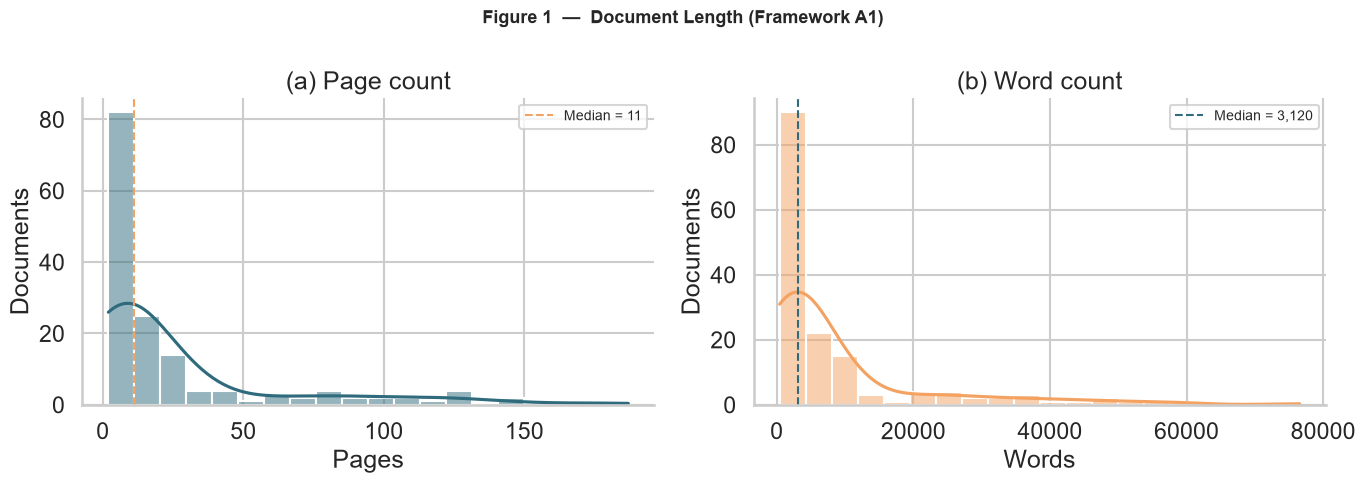

In [2]:
display(Markdown('**Table 1 — Extraction pipeline output sizes**'))
display(pd.DataFrame({
    'Output file': ['documents.csv', 'structural_core.csv', 'recommendations.csv', 'frames.csv'],
    'Rows': [len(documents), len(structural_core), len(recommendations), len(frames)],
    'Unique documents': [
        documents['doc_id'].nunique()       if len(documents)       else 0,
        structural_core['doc_id'].nunique() if len(structural_core) else 0,
        recommendations['doc_id'].nunique() if len(recommendations) else 0,
        frames['doc_id'].nunique()          if len(frames)          else 0,
    ],
}).set_index('Output file'))

_desc = (
    documents[['page_count', 'word_count']]
    .rename(columns={'page_count': 'Pages', 'word_count': 'Words'})
    .describe()
    .loc[['mean', '50%', 'std', 'min', 'max']]
    .rename(index={'50%': 'median'})
    .round(1)
)
display(Markdown('**Table 2 — Document length summary statistics**'))
display(_desc.T)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(analysis_df['A1_page_count'], bins=20, kde=True, ax=axes[0], color=C_PRIMARY)
axes[0].set_title('(a) Page count')
axes[0].set_xlabel('Pages')
axes[0].set_ylabel('Documents')
_med_p = analysis_df['A1_page_count'].median()
axes[0].axvline(_med_p, color=C_ACCENT, linestyle='--', linewidth=1.5, label=f'Median = {_med_p:.0f}')
axes[0].legend(fontsize=10)

if _has_col(documents, 'word_count'):
    sns.histplot(documents['word_count'].dropna(), bins=20, kde=True, ax=axes[1], color=C_ACCENT)
    axes[1].set_title('(b) Word count')
    axes[1].set_xlabel('Words')
    axes[1].set_ylabel('Documents')
    _med_w = documents['word_count'].median()
    axes[1].axvline(_med_w, color=C_PRIMARY, linestyle='--', linewidth=1.5, label=f'Median = {_med_w:,.0f}')
    axes[1].legend(fontsize=10)

fig.suptitle('Figure 1  —  Document Length (Framework A1)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 2. Validation and Cross-validation[](#2.-AI-Extraction-Quality:-Cross-Validation)

The analysis uses a **two-pass extraction design**. Pass 1 sends the full PDF text to the LLM, providing rich document-level context. Pass 2 re-runs the LLM over each isolated solution sentence identified in Pass 1, providing highly concentrated per-sentence context at the cost of losing broader document cues.

Extraction quality was assessed by comparing AI-extracted solution segments against **1,333 manually coded segments** across **106 documents**. Three agreement metrics are reported:

* **Presence agreement (A)**: do AI and manual coders agree on whether a document contains solutions at all?
* **Dominant-type agreement (B)**: among documents where both find solutions, does the most frequent extraction type match the manually assigned type?
* **Content overlap — exact (C)**: is the normalized text of a manual segment present as a substring in any AI extraction for the same document (or vice versa)?

Figure 2(a-i) shows the three validation metrics. Figure 2(a-ii) compares **field fill rates between Pass 1 (full-text) and Pass 2 (isolated snippet)** for four context-sensitive fields: actor type, target audience, expected outcomes, and instrument type. Fields whose extraction depends on information outside the solution sentence itself — such as actor type and instrument type — typically show lower fill rates in Pass 2.

Figure 2(b) summarises the AI–manual count agreement as a binned cross-table. Rows represent AI extraction counts per document; columns represent manual coding counts. Counts on the diagonal indicate agreement; off-diagonal counts indicate over- or under-extraction.

Figure 2(c) provides a full field-level comparison between Pass 1 and Pass 2, reporting fill rate and agreement rate for all shared fields, including `target_raw`, `expected_outcomes`, `implementation_steps`, and `trade_offs`.

AI solutions extracted:          1,041
Manually coded segments:         1,333
Documents with AI solutions:     152
Documents with manual solutions: 106


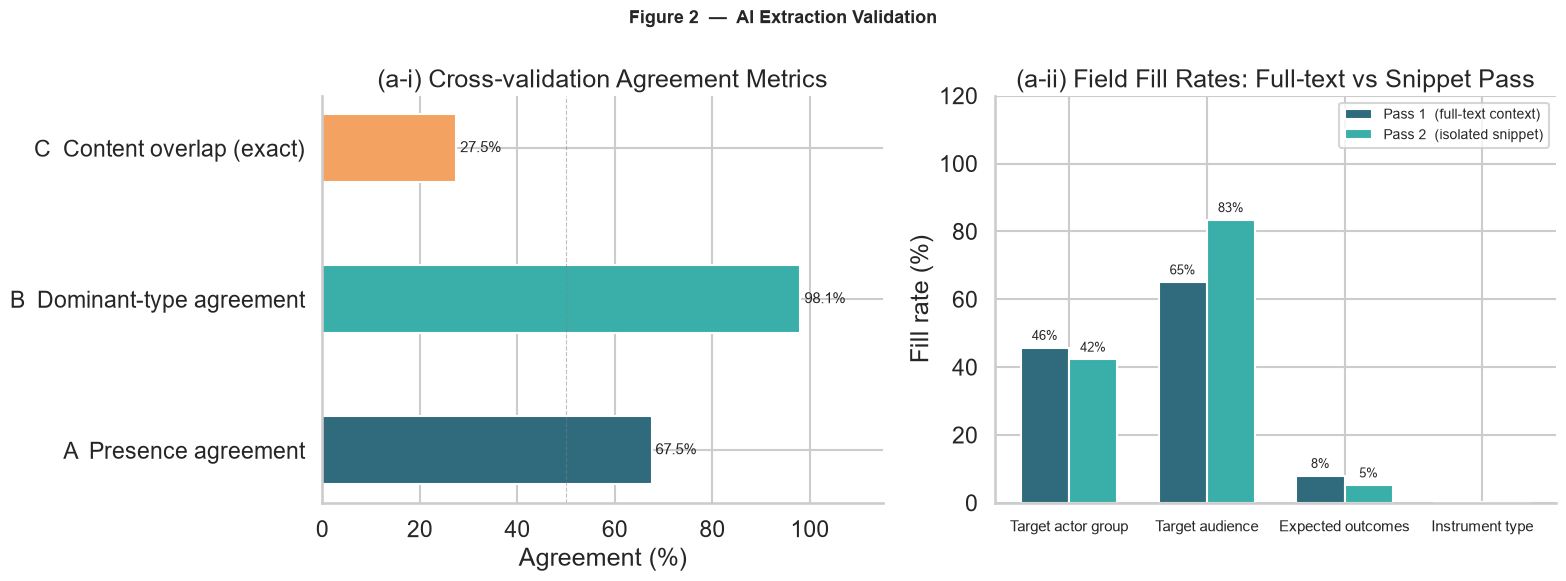

**Figure 2(b) — Binned solution-count cross-table (documents)**

Manual segments per doc →,0,1,2–3,4–6,7+
AI extractions per doc ↓,,,,,
0,0,0,0,0,2
1,3,1,2,0,0
2–3,8,3,4,2,4
4–6,20,1,5,20,8
7+,17,0,3,21,30


In [3]:
import json as _json

pov  = crossval_metrics.get('primary', {})
ov   = pov.get('overview', {})
pres = pov.get('presence_agreement', {})
typ  = pov.get('type_agreement', {})
ov_e = pov.get('overlap_exact', {})

# Load context comparison fill rates
_m_ctx = _json.loads((CROSSVAL_DIR / 'metrics.json').read_text()) if (CROSSVAL_DIR / 'metrics.json').exists() else {}
fill = _m_ctx.get('context_comparison', {}).get('fill_rates', {})

print(f"AI solutions extracted:          {ov.get('ai_total_solutions',  'n/a'):,}")
print(f"Manually coded segments:         {ov.get('manual_total_solutions', 'n/a'):,}")
print(f"Documents with AI solutions:     {ov.get('ai_solution_docs',    'n/a')}")
print(f"Documents with manual solutions: {ov.get('manual_solution_docs','n/a')}")

CONTEXT_KEY_FIELDS = {
    'actor_type':        'Target actor group',
    'target_raw':        'Target audience',
    'expected_outcomes': 'Expected outcomes',
    'instrument_type':   'Instrument type',
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── (a-i) Cross-validation agreement metrics ──────────────────────────
metrics_data = {
    'A  Presence agreement':       pres.get('rate', 0),
    'B  Dominant-type agreement':  typ.get('rate', 0),
    'C  Content overlap (exact)':  ov_e.get('overlap_rate', 0),
}
bar_colors = [C_PRIMARY, C_SECONDARY, C_ACCENT]
bars = axes[0].barh(
    list(metrics_data.keys()),
    [v * 100 for v in metrics_data.values()],
    color=bar_colors, edgecolor='white', height=0.45,
)
for bar, val in zip(bars, metrics_data.values()):
    axes[0].text(
        bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2,
        f'{val:.1%}', va='center', fontsize=11,
    )
axes[0].set_xlim(0, 115)
axes[0].axvline(50, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
axes[0].set_xlabel('Agreement (%)')
axes[0].set_title('(a-i) Cross-validation Agreement Metrics')

# ── (a-ii) P1 vs P2 fill rates for key context-sensitive fields ───────
ctx_labels = list(CONTEXT_KEY_FIELDS.values())
p1_vals = [(fill.get(f) or {}).get('pass1') or 0.0 for f in CONTEXT_KEY_FIELDS]
p2_vals = [(fill.get(f) or {}).get('pass2') or 0.0 for f in CONTEXT_KEY_FIELDS]
x2 = np.arange(len(CONTEXT_KEY_FIELDS))
w2 = 0.35

b1 = axes[1].bar(x2 - w2/2, [v * 100 for v in p1_vals], w2,
                 label='Pass 1  (full-text context)', color=C_PRIMARY, edgecolor='white')
b2 = axes[1].bar(x2 + w2/2, [v * 100 for v in p2_vals], w2,
                 label='Pass 2  (isolated snippet)',   color=C_SECONDARY, edgecolor='white')
for bar in list(b1) + list(b2):
    h = bar.get_height()
    if h > 2:
        axes[1].text(bar.get_x() + bar.get_width() / 2, h + 1.5,
                     f'{h:.0f}%', ha='center', va='bottom', fontsize=9)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(ctx_labels, fontsize=11)
axes[1].set_ylim(0, 120)
axes[1].set_ylabel('Fill rate (%)')
axes[1].legend(fontsize=10)
axes[1].set_title('(a-ii) Field Fill Rates: Full-text vs Snippet Pass')

fig.suptitle('Figure 2  —  AI Extraction Validation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ── Figure 2(b): Binned solution-count cross-table ────────────────────
if len(comparison_df) and 'ai_count' in comparison_df.columns and 'manual_count' in comparison_df.columns:
    _bins = [0, 1, 2, 4, 7, float('inf')]
    _lbls = ['0', '1', '2–3', '4–6', '7+']
    _ai_b  = pd.cut(comparison_df['ai_count'],     bins=_bins, labels=_lbls, right=False)
    _man_b = pd.cut(comparison_df['manual_count'], bins=_bins, labels=_lbls, right=False)
    _ct = pd.crosstab(_ai_b, _man_b)
    _ct.index.name   = 'AI extractions per doc  ↓'
    _ct.columns.name = 'Manual segments per doc  →'
    display(Markdown('**Figure 2(b) — Binned solution-count cross-table (documents)**'))
    display(_ct.style.background_gradient(cmap='Blues').format('{:,}'))

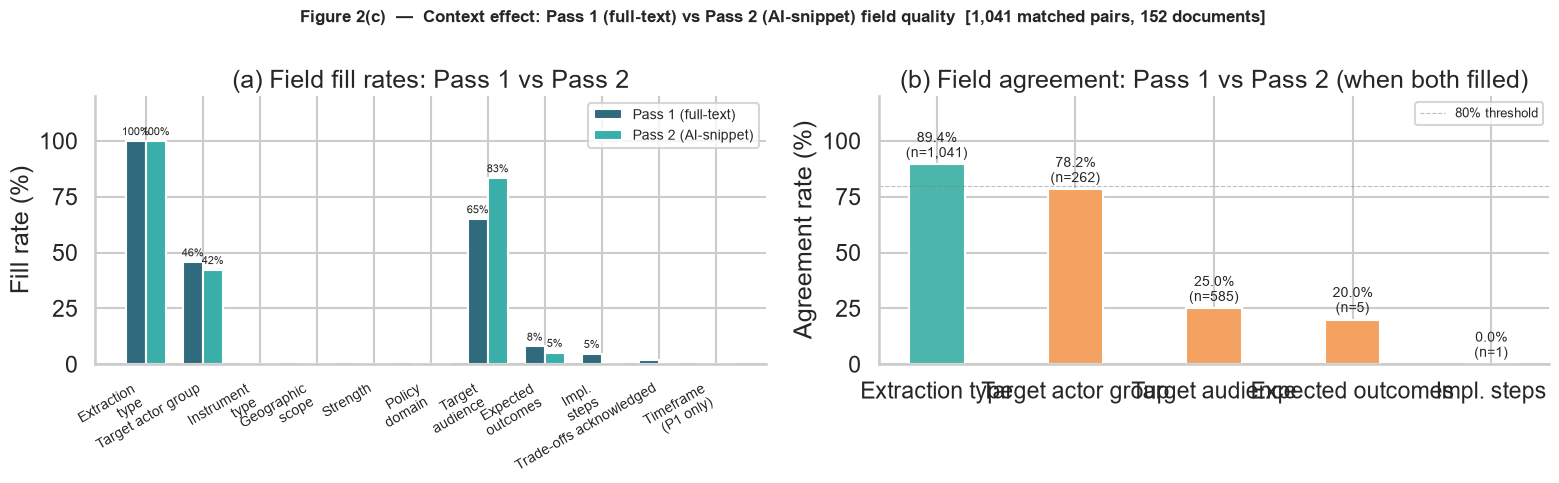

Key findings:
  actor_type: Pass 1 fill 45.7%  |  Pass 2 fill 42.3%
  target_raw: Pass 1 fill 65.0%  |  Pass 2 fill 83.4%
  extraction_type: Pass 1 fill 100.0%  |  Pass 2 fill 100.0%
  extraction_type agreement: 89.4%  (931/1041 pairs)
  Median confidence delta (Pass 2 - Pass 1): +0.00


In [4]:
import json as _json

# Reload metrics to pick up context_comparison section
_m = _json.loads((CROSSVAL_DIR / 'metrics.json').read_text())
cc   = _m.get('context_comparison', {})
fill = cc.get('fill_rates', {})
agr  = cc.get('agreement_rates', {})

FIELD_LABELS = {
    'extraction_type':      'Extraction\ntype',
    'actor_type':           'Target actor group',
    'instrument_type':      'Instrument\ntype',
    'geographic_scope':     'Geographic\nscope',
    'strength':             'Strength',
    'policy_domain':        'Policy\ndomain',
    'target_raw':           'Target\naudience',
    'expected_outcomes':    'Expected\noutcomes',
    'implementation_steps': 'Impl.\nsteps',
    'trade_offs':           'Trade-offs acknowledged',
    'timeframe':            'Timeframe\n(P1 only)',
}

fields   = list(FIELD_LABELS.keys())
p1_rates = [(fill.get(f) or {}).get('pass1') or 0.0 for f in fields]
p2_rates = [(fill.get(f) or {}).get('pass2') or 0.0 for f in fields]

x = np.arange(len(fields))
w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (a) Fill rates grouped bar
bars1 = axes[0].bar(x - w/2, [r * 100 for r in p1_rates], w,
                    label='Pass 1 (full-text)', color=C_PRIMARY, edgecolor='white')
bars2 = axes[0].bar(x + w/2, [r * 100 for r in p2_rates], w,
                    label='Pass 2 (AI-snippet)', color=C_SECONDARY, edgecolor='white')
for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    if h > 2:
        axes[0].text(bar.get_x() + bar.get_width() / 2, h + 1.5,
                     f'{h:.0f}%', ha='center', va='bottom', fontsize=8)
axes[0].set_xticks(x)
axes[0].set_xticklabels([FIELD_LABELS[f] for f in fields], rotation=30, ha='right', fontsize=10)
axes[0].set_ylabel('Fill rate (%)')
axes[0].set_ylim(0, 120)
axes[0].legend(fontsize=10)
axes[0].set_title('(a) Field fill rates: Pass 1 vs Pass 2')

# (b) Agreement rates (only fields with sufficient pairs)
agr_fields = [(f, FIELD_LABELS[f]) for f in FIELD_LABELS
              if agr.get(f, {}).get('total', 0) > 0]
agr_labels = [lbl.replace('\n', ' ') for _, lbl in agr_fields]
agr_rates  = [agr[f]['rate'] * 100 for f, _ in agr_fields]
agr_totals = [agr[f]['total'] for f, _ in agr_fields]
colors_agr = [C_AGREE if r >= 80 else C_ACCENT for r in agr_rates]

agr_bars = axes[1].bar(agr_labels, agr_rates, color=colors_agr, edgecolor='white', width=0.4)
for bar, r, n in zip(agr_bars, agr_rates, agr_totals):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
                 f'{r:.1f}%\n(n={n:,})', ha='center', va='bottom', fontsize=10)
axes[1].axhline(80, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, label='80% threshold')
axes[1].set_ylim(0, 120)
axes[1].set_ylabel('Agreement rate (%)')
axes[1].set_title('(b) Field agreement: Pass 1 vs Pass 2 (when both filled)')
axes[1].legend(fontsize=9)

fig.suptitle(
    f'Figure 2(c)  \u2014  Context effect: Pass 1 (full-text) vs Pass 2 (AI-snippet) field quality'
    f'  [{cc.get("matched_pairs", "n/a"):,} matched pairs, {cc.get("documents", "n/a")} documents]',
    fontsize=12, fontweight='bold',
)
plt.tight_layout()
plt.show()

print("Key findings:")
for f, lbl in [('actor_type', 'actor_type'), ('target_raw', 'target_raw'), ('extraction_type', 'extraction_type')]:
    fr = fill.get(f, {})
    p1v = fr.get('pass1')
    p2v = fr.get('pass2')
    p1s = f'{p1v:.1%}' if p1v is not None else 'n/a'
    p2s = f'{p2v:.1%}' if p2v is not None else 'n/a'
    print(f'  {lbl}: Pass 1 fill {p1s}  |  Pass 2 fill {p2s}')
if agr.get('extraction_type', {}).get('rate') is not None:
    a = agr['extraction_type']
    print(f"  extraction_type agreement: {a['rate']:.1%}  ({a['agreed']}/{a['total']} pairs)")
if cc.get('confidence_delta_median') is not None:
    print(f"  Median confidence delta (Pass 2 - Pass 1): {cc['confidence_delta_median']:+.2f}")

## 3. Framework Results

### B. Content structure: problem, solutions, and implementation[](#3.-Content-Structure-(Framework-B))

Dimensions B2–B4 form the structural backbone of a policy brief: problem identification, explicit solutions, and implementation considerations. Together they assess whether the brief fulfils the basic communicative function of a policy document — presenting a problem and a plausible pathway toward addressing it.

| Dimension | Indicator | Values |
| --- | --- | --- |
| B2 | Problem identified | present / weak / absent |
| B3 | Solutions explicit | present / weak / absent |
| B4 | Implementation discussed | present / weak / absent |

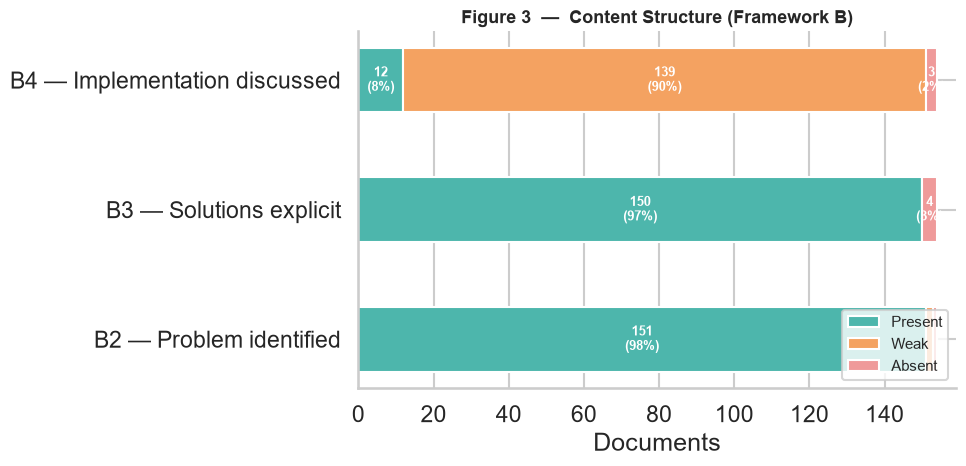

,Present (n),Present (%),Weak (n),Weak (%),Absent (n),Absent (%)
Dimension,,,,,,
B2 — Problem identified,151,98%,2,1%,1,1%
B3 — Solutions explicit,150,97%,0,0%,4,3%
B4 — Implementation discussed,12,8%,139,90%,3,2%


In [5]:
STATUS_COLORS = {
    'present': C_AGREE,
    'weak':    C_ACCENT,
    'absent':  C_DISAGREE,
}

dims_b = [
    ('B2_problem_identified',    'B2 — Problem identified'),
    ('B3_solutions_status',      'B3 — Solutions explicit'),
    ('B4_implementation_status', 'B4 — Implementation discussed'),
]

N = len(analysis_df)
available_b = [(c, t) for c, t in dims_b if c in analysis_df.columns]
dim_labels  = [t for _, t in available_b]
levels      = ['present', 'weak', 'absent']

fig, ax = plt.subplots(figsize=(10, 5))
left = np.zeros(len(available_b))

for level in levels:
    counts = np.array([
        int((analysis_df[col].astype(str).str.lower() == level).sum())
        for col, _ in available_b
    ])
    bars = ax.barh(dim_labels, counts, left=left,
                   color=STATUS_COLORS[level], edgecolor='white',
                   label=level.capitalize(), height=0.5)
    for bar, cnt in zip(bars, counts):
        if cnt > 2:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                f'{cnt}\n({cnt / N:.0%})',
                ha='center', va='center', fontsize=9,
                color='white', fontweight='bold',
            )
    left = left + counts

ax.set_xlim(0, N + 5)
ax.set_xlabel('Documents')
ax.legend(loc='lower right', fontsize=11)
ax.set_title('Figure 3  —  Content Structure (Framework B)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Summary table
rows_b = []
for col, label in available_b:
    s = analysis_df[col].astype(str).str.lower()
    rows_b.append({
        'Dimension':     label,
        'Present (n)':   int((s == 'present').sum()),
        'Present (%)':   f'{(s == "present").mean():.0%}',
        'Weak (n)':      int((s == 'weak').sum()),
        'Weak (%)':      f'{(s == "weak").mean():.0%}',
        'Absent (n)':    int((s == 'absent').sum()),
        'Absent (%)':    f'{(s == "absent").mean():.0%}',
    })
if rows_b:
    display(pd.DataFrame(rows_b).set_index('Dimension'))

### C-D. Action orientation and facilitating role[](#4.-Action-Orientation-(Frameworks-C-&-D))

The **bridging role** (C) assesses whether a brief specifies *how* to act (C5 procedural clarity), *who* should act (C6 responsibility), and what outcomes are anticipated (C7). The **facilitating role** (D) extends this by asking whether the brief discusses broader impacts (D8), trade-offs between options (D9), and concrete policy alternatives (D10).

Together these six dimensions measure the brief's *action-orientation* — its capacity to guide policy actors toward concrete decisions. Figure 4 shows the percentage of documents meeting each criterion; the dashed line marks the 50% threshold. Note: C5 reflects procedural clarity or, where that field is absent, implementation status as a proxy.

In [6]:
MANUAL_SNIPPET_CANDIDATES = [
    OUTPUT_DIR / 'recommendations_snippet_manual.csv',
    CROSSVAL_DIR / 'recommendations_snippet_manual.csv',
]
AI_FULL_TEXT_CANDIDATES = [
    OUTPUT_DIR / 'recommendations.csv',
]
MANUAL_REPORT_LABEL = 'Human-identified recommendation passages (LLM-assisted field extraction)'
AI_REPORT_LABEL = 'LLM extraction from complete policy briefs'

def _load_first_existing(paths):
    for path in paths:
        if path.exists():
            return pd.read_csv(path), path
    return pd.DataFrame(), None

manual_recs, manual_recs_path = _load_first_existing(MANUAL_SNIPPET_CANDIDATES)
ai_recs, ai_recs_path = _load_first_existing(AI_FULL_TEXT_CANDIDATES)

if len(manual_recs):
    if 'actor_raw' not in manual_recs.columns and 'actor_text_raw' in manual_recs.columns:
        manual_recs['actor_raw'] = manual_recs['actor_text_raw']
    if 'target_raw' not in manual_recs.columns and 'target_text_raw' in manual_recs.columns:
        manual_recs['target_raw'] = manual_recs['target_text_raw']

report_sources = []
if len(manual_recs):
    manual_recs = manual_recs.copy()
    manual_recs['provenance'] = manual_recs.get(
        'source_provenance', 'manually_coded_recommendation_segment'
    )
    report_sources.append(manual_recs)
else:
    print('warning: manually coded recommendation-segment output not found; downstream comparisons will skip that provenance')

if len(ai_recs):
    ai_recs = ai_recs.copy()
    ai_recs['provenance'] = ai_recs.get('source_provenance', 'full_policy_brief_text')
    report_sources.append(ai_recs)

report_recommendations = pd.concat(report_sources, ignore_index=True, sort=False) if report_sources else pd.DataFrame()

if len(report_recommendations):
    provenance_labels = {
        'manually_coded_recommendation_segment': MANUAL_REPORT_LABEL,
        'full_policy_brief_text': AI_REPORT_LABEL,
    }
    provenance_tag = report_recommendations['provenance'].map(provenance_labels).fillna(
        report_recommendations['provenance']
    )
    report_recommendations['actor_source_label'] = provenance_tag
    report_recommendations['target_source_label'] = provenance_tag
    display(Markdown('**Downstream provenance sources**'))
    display(pd.DataFrame({
        'Source': [MANUAL_REPORT_LABEL, AI_REPORT_LABEL],
        'Available rows': [len(manual_recs), len(ai_recs)],
        'File': [str(manual_recs_path) if manual_recs_path else 'missing', str(ai_recs_path) if ai_recs_path else 'missing'],
    }))
else:
    print('warning: no downstream recommendation sources available for source-aware reporting')

if len(report_recommendations):
    derived_dir = OUTPUT_DIR / 'reporting'
    derived_dir.mkdir(parents=True, exist_ok=True)
    if len(manual_recs):
        manual_recs.to_csv(derived_dir / 'recommendations_manual_segment_llm_reporting.csv', index=False)
    if len(ai_recs):
        ai_recs.to_csv(derived_dir / 'recommendations_ai_full_text_reporting.csv', index=False)
    report_recommendations.to_csv(derived_dir / 'recommendations_combined_by_provenance.csv', index=False)
    print(f'Prepared source-aware reporting tables in {derived_dir}')

**Downstream provenance sources**

,Source,Available rows,File
0,Human-identified recommendation passages (LLM-...,2023,C:\Users\DaSchulz\OneDrive - European Forest I...
1,LLM extraction from complete policy briefs,1038,C:\Users\DaSchulz\OneDrive - European Forest I...


Prepared source-aware reporting tables in C:\Users\DaSchulz\OneDrive - European Forest Institute\Dokumente\research\PolicyBriefAnalysis\dev\PolicyBriefAnalysis\output\reporting


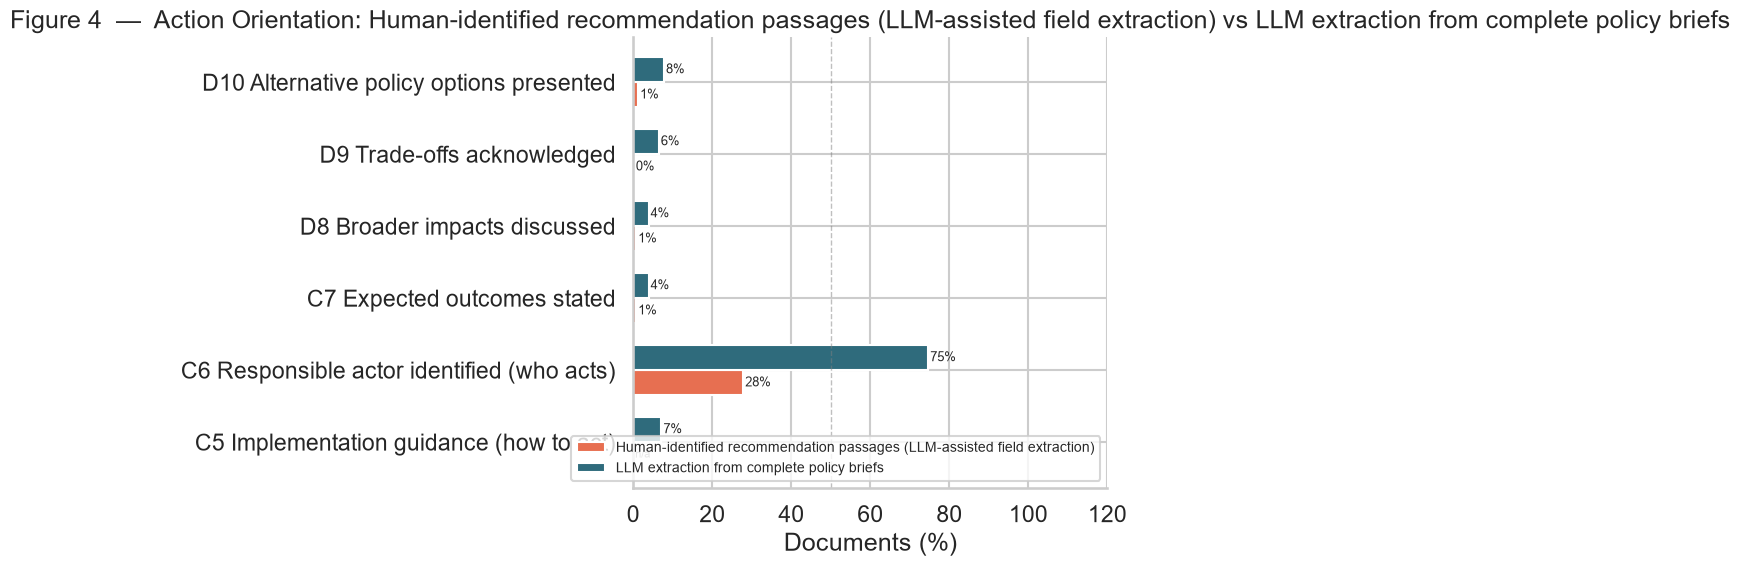

,Human-identified recommendation passages (LLM-assisted field extraction),LLM extraction from complete policy briefs
Dimension,,
C5 Implementation guidance (how to act),NaN,7.142857
C6 Responsible actor identified (who acts),27.834041,74.675325
C7 Expected outcomes stated,0.751388,3.896104
D8 Broader impacts discussed,0.751388,3.896104
D9 Trade-offs acknowledged,0.163345,6.493506
D10 Alternative policy options presented,1.241424,7.792208


In [7]:
indicators_cd = [
    ('C5 Implementation guidance (how to act)',   'C5_procedural_clarity',    'C'),
    ('C6 Responsible actor identified (who acts)',       'C6_responsibility',         'C'),
    ('C7 Expected outcomes stated', 'C7_anticipated_outcomes',   'C'),
    ('D8 Broader impacts discussed',      'D8_impacts_proxy',          'D'),
    ('D9 Trade-offs acknowledged',           'D9_tradeoffs',              'D'),
    ('D10 Alternative policy options presented',      'D10_policy_options',        'D'),
]

if len(report_recommendations):
    fig, ax = plt.subplots(figsize=(10, 6))
    plot_rows = []

    actor_col = 'actor_raw' if 'actor_raw' in report_recommendations.columns else None
    ext_col = 'extraction_type' if 'extraction_type' in report_recommendations.columns else None
    manual_provenance = 'manually_coded_recommendation_segment'
    has_manual = report_recommendations['provenance'].eq(manual_provenance).any()

    for label, col, group in indicators_cd:
        if col not in analysis_df.columns:
            continue

        ai_col = analysis_df[col]
        ai_pct = float((ai_col == 'present').mean()) if 'present' in ai_col.values else float(ai_col.astype(bool).mean())

        manual_pct = np.nan
        if ext_col is not None and has_manual:
            manual_rows = report_recommendations['provenance'].eq(manual_provenance)
            if label.startswith('C6'):
                actor_non_null = report_recommendations[actor_col].notna() if actor_col is not None else pd.Series(False, index=report_recommendations.index)
                manual_mask = manual_rows & report_recommendations[ext_col].isin(RECOMMENDATION_ANALYSIS_TYPES) & actor_non_null
                manual_pct = float(manual_mask.mean()) if len(manual_mask) else np.nan
            elif label.startswith('C7') or label.startswith('D8'):
                manual_mask = manual_rows & report_recommendations[ext_col].eq('expected_outcome')
                manual_pct = float(manual_mask.mean()) if len(manual_mask) else np.nan
            elif label.startswith('D9'):
                manual_mask = manual_rows & report_recommendations[ext_col].eq('trade_off')
                manual_pct = float(manual_mask.mean()) if len(manual_mask) else np.nan
            elif label.startswith('D10'):
                manual_mask = manual_rows & report_recommendations[ext_col].eq('policy_option')
                manual_pct = float(manual_mask.mean()) if len(manual_mask) else np.nan

        plot_rows.append({
            'label': label,
            'manual_pct': manual_pct * 100 if pd.notna(manual_pct) else np.nan,
            'ai_pct': ai_pct * 100,
            'group': group,
        })

    df_cd = pd.DataFrame(plot_rows)
    if not df_cd.empty:
        y = np.arange(len(df_cd))
        h = 0.35

        manual_vals = df_cd['manual_pct'].fillna(0)
        manual_bars = ax.barh(y - h/2, manual_vals, height=h, color=C_WARM, edgecolor='white', label=MANUAL_REPORT_LABEL)
        ai_bars = ax.barh(y + h/2, df_cd['ai_pct'], height=h, color=C_PRIMARY, edgecolor='white', label=AI_REPORT_LABEL)

        for bar, val in zip(ai_bars, df_cd['ai_pct']):
            ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, f'{val:.0f}%', va='center', fontsize=9)

        for bar, val in zip(manual_bars, df_cd['manual_pct']):
            if pd.notna(val):
                ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, f'{val:.0f}%', va='center', fontsize=9)
            else:
                ax.text(0.5, bar.get_y() + bar.get_height() / 2, 'n/a', va='center', fontsize=8, color='gray')

        ax.set_yticks(y)
        ax.set_yticklabels(df_cd['label'])
        ax.set_xlim(0, 120)
        ax.set_xlabel('Documents (%)')
        ax.axvline(50, color='gray', linestyle='--', linewidth=1, alpha=0.5)
        ax.legend(loc='lower right', fontsize=10)
        ax.set_title(f'Figure 4  —  Action Orientation: {MANUAL_REPORT_LABEL} vs {AI_REPORT_LABEL}')
        plt.tight_layout()
        plt.show()

        display(
            df_cd[['label', 'manual_pct', 'ai_pct']]
            .rename(columns={'label': 'Dimension', 'manual_pct': MANUAL_REPORT_LABEL, 'ai_pct': AI_REPORT_LABEL})
            .set_index('Dimension')
        )
else:
    print('Source-aware Figure 4 skipped because no downstream recommendation sources were available.')

### E. Accessibility and readability[](#5.-Accessibility-(Framework-E))

Dimensions E12–E14 measure language complexity indicators that affect how easily a non-specialist policy audience can engage with a brief. Average sentence length and lexical diversity describe structural text complexity; Flesch Reading Ease and Flesch-Kincaid Grade Level provide standardized readability benchmarks (higher Flesch = easier; higher FK grade = harder).

Table 3 summarizes the key statistics; Figure 5 shows the full distribution of each indicator across the corpus.

**Table 3 — Accessibility indicator summary statistics (Framework E)**

,mean,median,std,min,max
Avg sentence length (words),22.65,22.52,4.77,12.23,45.78
Lexical diversity,0.36,0.37,0.12,0.10,0.63
Flesch reading ease,20.59,20.24,8.89,-14.51,44.38
Flesch-Kincaid grade level,15.68,15.73,1.84,10.96,24.67


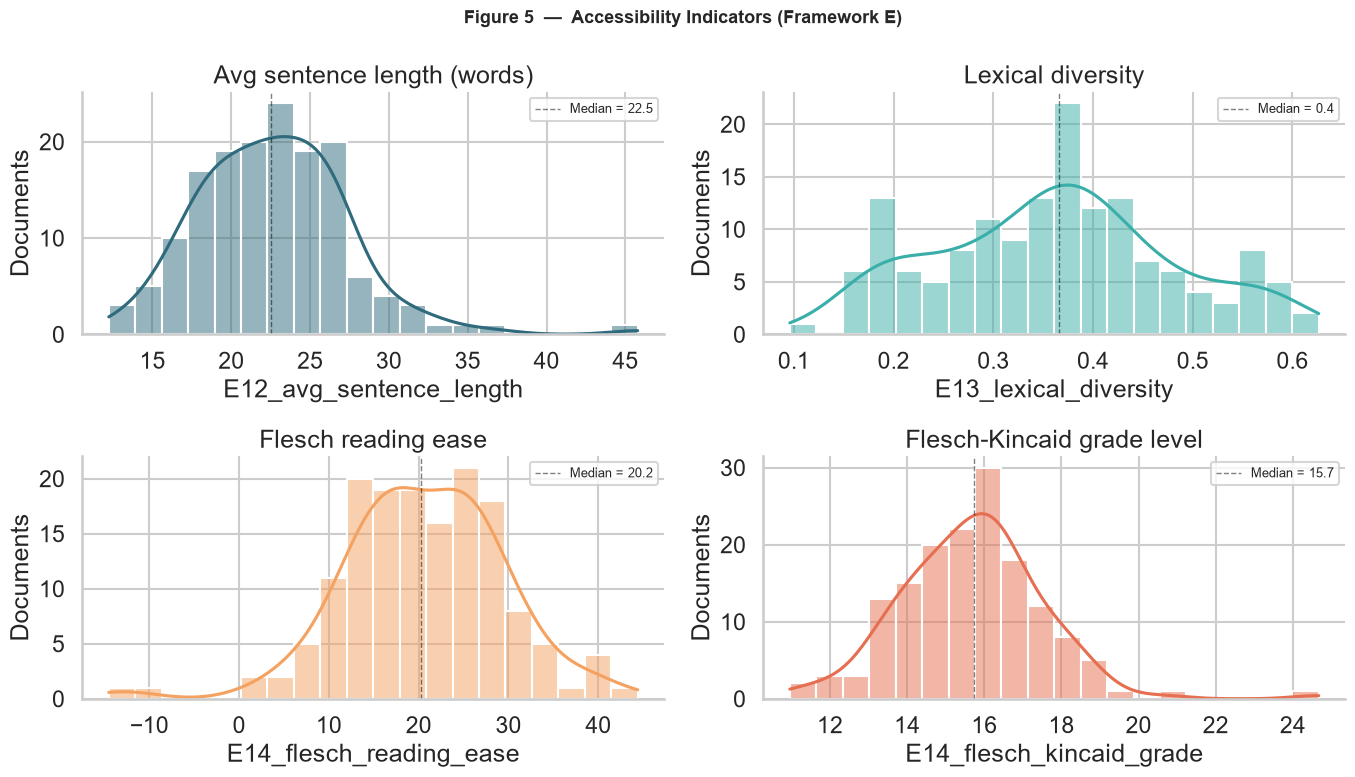

In [8]:
access_items = [
    ('Avg sentence length (words)', 'E12_avg_sentence_length'),
    ('Lexical diversity',           'E13_lexical_diversity'),
    ('Flesch reading ease',         'E14_flesch_reading_ease'),
    ('Flesch-Kincaid grade level',  'E14_flesch_kincaid_grade'),
]
avail_a = [(l, c) for l, c in access_items if c in analysis_df.columns and analysis_df[c].notna().any()]

if avail_a:
    stats_a = pd.DataFrame({
        l: analysis_df[c].describe()[['mean', '50%', 'std', 'min', 'max']]
        for l, c in avail_a
    }).T.rename(columns={'50%': 'median'}).round(2)
    display(Markdown('**Table 3 — Accessibility indicator summary statistics (Framework E)**'))
    display(stats_a)

    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    axes = axes.flatten()
    palette = [C_PRIMARY, C_SECONDARY, C_ACCENT, C_WARM]
    for ax, (label, col), c in zip(axes, avail_a, palette):
        data = analysis_df[col].dropna()
        sns.histplot(data, bins=20, kde=True, ax=ax, color=c)
        ax.axvline(data.median(), color='black', linestyle='--', linewidth=1,
                   alpha=0.5, label=f'Median = {data.median():.1f}')
        ax.set_title(label)
        ax.set_ylabel('Documents')
        ax.legend(fontsize=9)
    for ax in axes[len(avail_a):]:
        ax.set_visible(False)

    fig.suptitle('Figure 5  —  Accessibility Indicators (Framework E)', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('Accessibility columns not available.')

### F-G. Narrative framing and transparency[](#6.-Narrative-&-Transparency-(Frameworks-F-&-G))

**F15 Narrative hook** assesses whether the brief opens with an engaging device — a striking statistic, anecdote, scenario, or question — intended to draw the reader in before the substantive content. The hook-type breakdown shows which rhetorical devices are most common among briefs that use them.

**G16 Funding disclosure** and **G18 Contact information** are basic transparency indicators: does the brief acknowledge who funded the underlying research, and does it provide a means for policy actors to reach the authors?

Figure 6 shows these three dimensions as a combined panel.

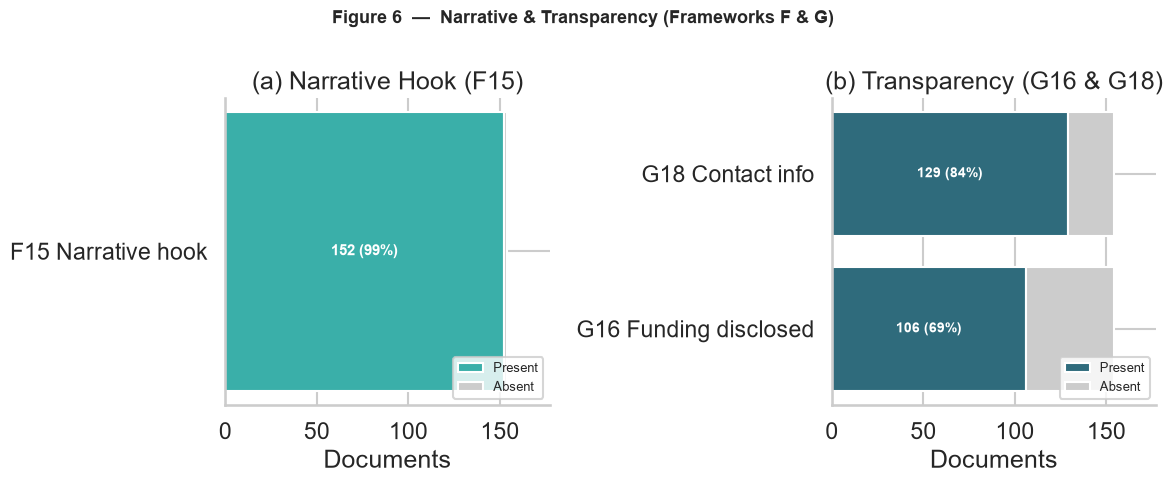

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# (a) Narrative hook: present vs absent (horizontal stacked)
if 'F15_narrative_hook' in analysis_df.columns:
    hook_n  = int(analysis_df['F15_narrative_hook'].astype(bool).sum())
    hook_ab = len(analysis_df) - hook_n
    axes[0].barh(['F15 Narrative hook'], [hook_n],  color=C_SECONDARY, edgecolor='white', label='Present')
    axes[0].barh(['F15 Narrative hook'], [hook_ab], left=[hook_n], color='#cccccc', edgecolor='white', label='Absent')
    axes[0].text(hook_n / 2, 0, f'{hook_n} ({hook_n / len(analysis_df):.0%})',
                 ha='center', va='center', color='white', fontsize=11, fontweight='bold')
    axes[0].set_xlim(0, len(analysis_df) * 1.15)
    axes[0].set_xlabel('Documents')
    axes[0].set_title('(a) Narrative Hook (F15)')
    axes[0].legend(fontsize=9, loc='lower right')
else:
    axes[0].set_visible(False)

# (b) Transparency: G16 funding + G18 contact (horizontal stacked)
transp_items_g = [('G16 Funding disclosed', 'G16_funding'), ('G18 Contact info', 'G18_contact_info')]
t_rows = []
for label, col in transp_items_g:
    if col not in analysis_df.columns:
        continue
    s = analysis_df[col]
    n = int(s.astype(bool).sum()) if s.notna().any() else 0
    t_rows.append((label, n, len(analysis_df) - n))

if t_rows:
    t_labels  = [r[0] for r in t_rows]
    t_present = [r[1] for r in t_rows]
    t_absent  = [r[2] for r in t_rows]
    axes[1].barh(t_labels, t_present, color=C_PRIMARY,   edgecolor='white', label='Present')
    axes[1].barh(t_labels, t_absent,  left=t_present, color='#cccccc', edgecolor='white', label='Absent')
    for i, p in enumerate(t_present):
        axes[1].text(p / 2, i, f'{p} ({p / len(analysis_df):.0%})',
                     ha='center', va='center', color='white', fontsize=10, fontweight='bold')
    axes[1].set_xlim(0, len(analysis_df) * 1.15)
    axes[1].set_xlabel('Documents')
    axes[1].set_title('(b) Transparency (G16 & G18)')
    axes[1].legend(fontsize=9, loc='lower right')
else:
    axes[1].set_visible(False)

fig.suptitle('Figure 6  —  Narrative & Transparency (Frameworks F & G)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### H. Policy-instrument frames[](#7.-Policy-Instrument-Types-(Framework-H))

Dimensions H19–H23 classify each brief against five canonical policy-instrument types derived from the theoretical literature:

| # | Frame | Description |
| --- | --- | --- |
| H19 | Command-and-Control | Regulatory mandates, standards, prohibitions |
| H20 | Economic Instruments | Taxes, subsidies, market mechanisms |
| H21 | Self-Regulation | Voluntary standards set by industry/profession |
| H22 | Voluntarism | Voluntary actions without binding standards |
| H23 | Information Strategies | Education, labelling, awareness campaigns |

A brief exhibiting two or more types constitutes a **policy mix** (H24). Figure 7(a) shows how many documents contain each frame; Figure 7(b) shows the co-occurrence matrix — how often each pair of frames appears together in the same document.

Policy mix (H24, ≥2 frames present): 72 / 154 (47%)


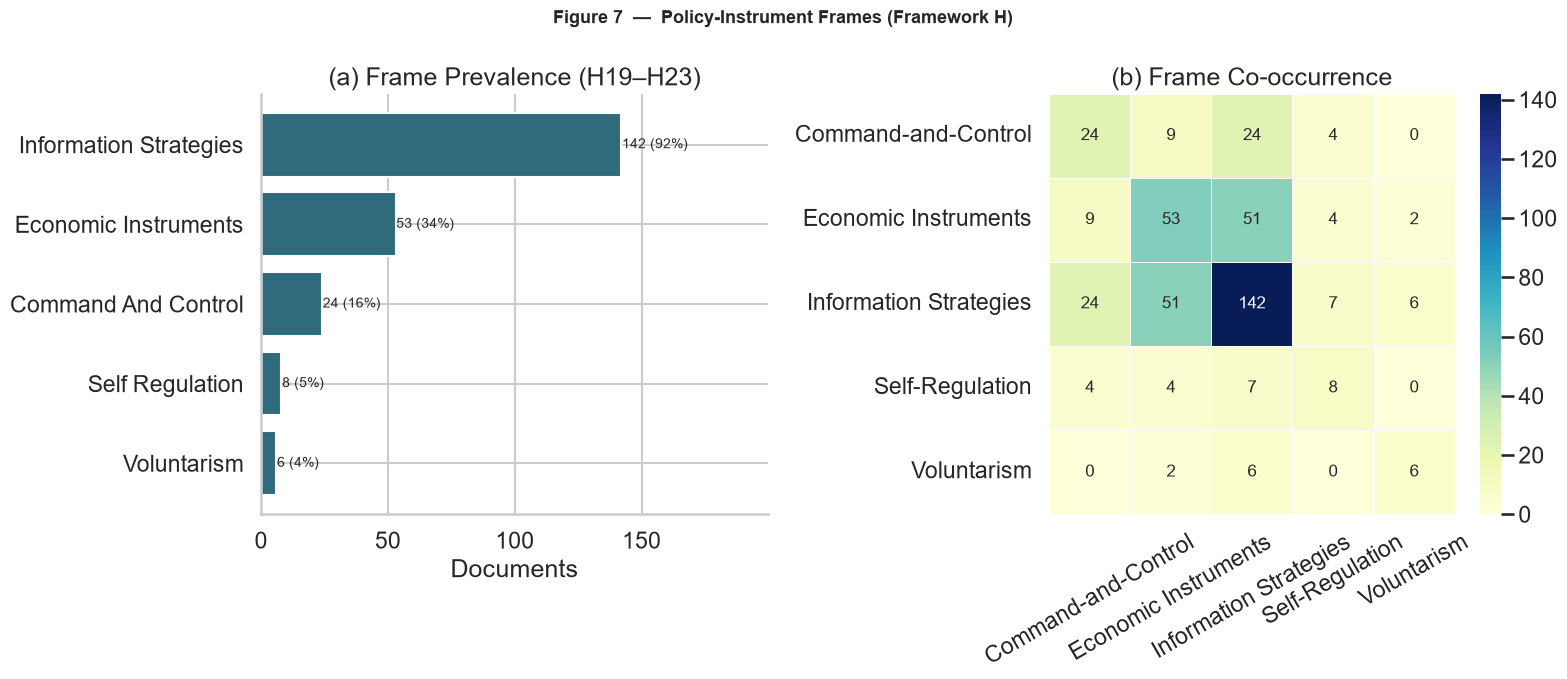

In [10]:
h_cols = [
    c for c in analysis_df.columns
    if c.startswith('H_') and c not in ('H_frames_present_count', 'H24_policy_mix')
]

if h_cols:
    mix_n   = int(analysis_df['H24_policy_mix'].astype(bool).sum()) if 'H24_policy_mix' in analysis_df.columns else 0
    mix_pct = mix_n / len(analysis_df)
    print(f'Policy mix (H24, ≥2 frames present): {mix_n} / {len(analysis_df)} ({mix_pct:.0%})')

    frame_prev = analysis_df[h_cols].sum().sort_values()
    frame_prev.index = [c.replace('H_', '').replace('_', ' ').title() for c in frame_prev.index]

    fig = plt.figure(figsize=(16, 7))
    ax1 = fig.add_subplot(1, 2, 1)
    ax2 = fig.add_subplot(1, 2, 2)

    bars = ax1.barh(frame_prev.index, frame_prev.values, color=C_PRIMARY, edgecolor='white')
    for bar, v in zip(bars, frame_prev.values):
        ax1.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
                 f'{v} ({v / len(analysis_df):.0%})', va='center', fontsize=10)
    ax1.set_xlim(0, frame_prev.values.max() * 1.4 + 1)
    ax1.set_xlabel('Documents')
    ax1.set_title('(a) Frame Prevalence (H19–H23)')

    if len(frames):
        _fp2  = frames[frames['decision'] == 'present']
        _pm   = _fp2.assign(v=1).pivot_table(
            index='doc_id', columns='frame_label', values='v', fill_value=0
        )
        _cooc = _pm.T.dot(_pm)
        sns.heatmap(
            _cooc, annot=True, fmt='.0f', cmap='YlGnBu',
            linewidths=0.5, ax=ax2, annot_kws={'size': 12},
        )
        ax2.set_title('(b) Frame Co-occurrence')
        ax2.set_xlabel('')
        ax2.set_ylabel('')
        ax2.tick_params(axis='x', rotation=30)

    fig.suptitle('Figure 7  —  Policy-Instrument Frames (Framework H)', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('Frame columns (H_*) not found in analysis_df — check frames.csv and setup cell.')

## 5. Recommendation pathways[](#8.-Recommendation-Pathways-(Sankey))

This section maps how recommendations flow from the **issuing institution** (by dominant affiliation type per document) through the **extraction type** (the semantic role of the recommendation — e.g. policy option, regulatory measure, actor responsibility) to the **target actor type** (who the recommendation is directed at).

Each link width is proportional to the number of recommendation records taking that path. The chart highlights which affiliation types tend to produce different recommendation styles and which actor types are most frequently targeted. This figure remains separate from the new source-aware manual-vs-AI downstream comparison used earlier in the section.

In [11]:
from IPython.display import Image, display

try:
    import plotly.graph_objects as go
    _plotly_ok = True
except ImportError:
    print("plotly not installed — run: pip install plotly>=5.0.0")
    _plotly_ok = False

if _plotly_ok and len(recommendation_content) and len(documents):
    from collections import Counter

    # ── dominant affiliation type per document ────────────────────────
    def _dominant_affil(s):
        if pd.isna(s) or str(s).strip() == '':
            return 'Other'
        parts = [t.strip() for t in str(s).split(';') if t.strip()]
        return Counter(parts).most_common(1)[0][0] if parts else 'Other'

    _doc_affil = (
        documents.set_index('doc_id')['fm_affiliation_types']
        .apply(_dominant_affil)
        if 'fm_affiliation_types' in documents.columns
        else pd.Series('Other', index=documents['doc_id'])
    )

    recs_s = recommendation_content.copy()
    recs_s['affiliation']   = recs_s['doc_id'].map(_doc_affil).fillna('Other')
    recs_s['ext_type']      = recs_s['extraction_type'].fillna('unknown')
    recs_s['actor']         = recs_s['actor_type'].fillna('Unspecified')

    # ── build node list: affiliation → ext_type → actor ──────────────
    affiliations = sorted(recs_s['affiliation'].unique())
    ext_types    = sorted(recs_s['ext_type'].unique())
    actors       = sorted(recs_s['actor'].unique())

    nodes      = affiliations + ext_types + actors
    node_idx   = {n: i for i, n in enumerate(nodes)}
    node_color = (
        ['#2F6B7C'] * len(affiliations) +
        ['#3AAFA9'] * len(ext_types) +
        ['#F4A261'] * len(actors)
    )

    src, tgt, val = [], [], []

    for (a, e), cnt in recs_s.groupby(['affiliation', 'ext_type']).size().items():
        src.append(node_idx[a]); tgt.append(node_idx[e]); val.append(int(cnt))

    for (e, ac), cnt in recs_s.groupby(['ext_type', 'actor']).size().items():
        src.append(node_idx[e]); tgt.append(node_idx[ac]); val.append(int(cnt))

    fig8 = go.Figure(go.Sankey(
        arrangement='snap',
        node=dict(
            label=nodes,
            color=node_color,
            pad=20,
            thickness=18,
            line=dict(color='white', width=0.5),
        ),
        link=dict(source=src, target=tgt, value=val, color='rgba(100,160,180,0.25)'),
    ))
    fig8.update_layout(
        title_text='Figure 8  —  Recommendation Pathways: Issuing Institution → Type → Target Actor',
        title_font_size=14,
        font_size=11,
        height=600,
    )
    fig8.show()

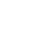

In [12]:
if len(report_recommendations):
    actor_df = report_recommendations.copy()
    actor_df['provenance_label'] = actor_df['provenance'].map({'manual_coded': 'Human-identified passages', 'ai_full_text': 'Full-brief LLM extraction'})

    actor_col = 'actor_type' if 'actor_type' in actor_df.columns else None
    if actor_col is None:
        actor_df['issuing_actor_group'] = 'Unspecified'
    else:
        actor_df['issuing_actor_group'] = actor_df[actor_col].fillna('unspecified').astype(str).str.lower()

    target_col = 'target_raw' if 'target_raw' in actor_df.columns else ('target_text_raw' if 'target_text_raw' in actor_df.columns else None)

    def _bucket_target(text):
        if pd.isna(text):
            return 'unspecified'
        t = str(text).lower().strip()
        if not t:
            return 'unspecified'
        if any(k in t for k in ['government', 'ministry', 'policy maker', 'policymaker', 'public authority', 'administration']):
            return 'government'
        if any(k in t for k in ['eu', 'european commission', 'european union']):
            return 'eu_institutions'
        if any(k in t for k in ['un ', 'united nations', 'fao', 'world bank', 'international']):
            return 'international_organizations'
        if any(k in t for k in ['company', 'industry', 'business', 'private sector', 'enterprise']):
            return 'private_sector'
        if any(k in t for k in ['ngo', 'civil society', 'community', 'citizen']):
            return 'civil_society'
        if any(k in t for k in ['research', 'university', 'academic', 'scientist']):
            return 'research_institutions'
        if any(k in t for k in ['farmer', 'household', 'individual', 'consumer']):
            return 'individuals'
        return 'other'

    if target_col is None:
        actor_df['target_actor_group'] = 'unspecified'
    else:
        actor_df['target_actor_group'] = actor_df[target_col].apply(_bucket_target)

    def _relative_stack(ax, value_col, title):
        counts = actor_df.groupby([value_col, 'provenance_label']).size().unstack(fill_value=0)
        counts = counts.sort_values(by=counts.columns.tolist(), ascending=False)
        if counts.empty:
            ax.set_visible(False)
            return

        shares = counts.div(counts.sum(axis=1), axis=0) * 100
        manual_vals = shares['Human-identified passages'] if 'Human-identified passages' in shares.columns else pd.Series(0, index=shares.index)
        ai_vals = shares['Full-brief LLM extraction'] if 'Full-brief LLM extraction' in shares.columns else pd.Series(0, index=shares.index)

        ax.barh(shares.index, manual_vals, color=C_WARM, edgecolor='white', label='Human-identified passages')
        ax.barh(shares.index, ai_vals, left=manual_vals, color=C_PRIMARY, edgecolor='white', label='Full-brief LLM extraction')
        ax.set_xlim(0, 100)
        ax.set_xlabel('Share within actor category (%)')
        ax.set_title(title)

    fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharex=True)
    _relative_stack(axes[0], 'issuing_actor_group', 'Figure 4(b)  —  Issuing actor provenance mix')
    _relative_stack(axes[1], 'target_actor_group', 'Figure 4(b)  —  Target actor provenance mix')
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False)
    plt.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()
else:
    print('Source-aware actor chart skipped because no downstream recommendation sources were available.')

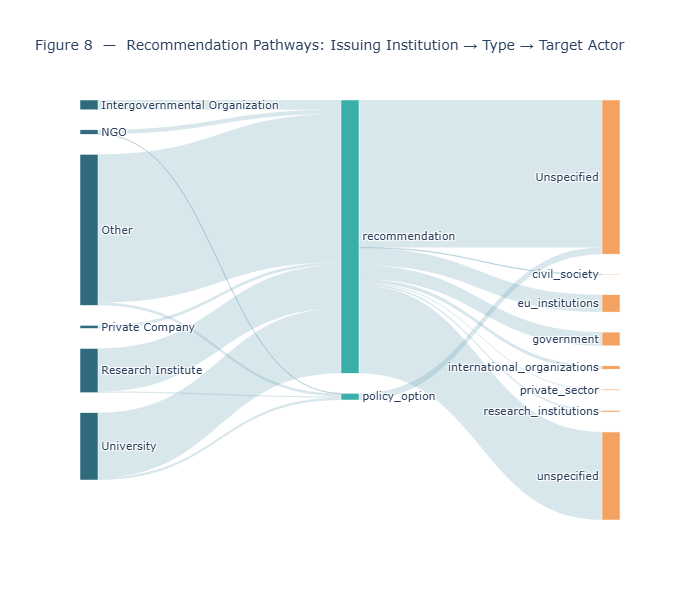

In [13]:
from IPython.display import Image
fig8.write_image("fig8.png")
Image("fig8.png")

### A. Document structure and corpus scope

Document length and corpus composition provide the baseline for interpreting all subsequent framework indicators.

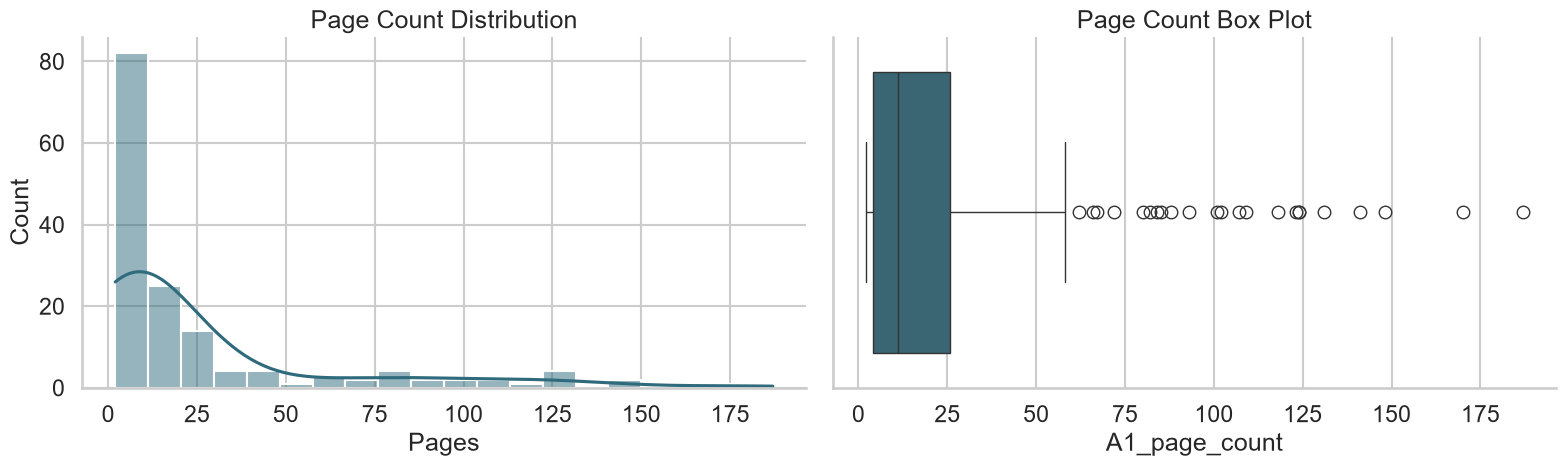

,count,mean,std,min,25%,50%,75%,max
Page Count,154.0,26.194805,37.785095,2.0,4.0,11.0,25.75,187.0


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(analysis_df['A1_page_count'], bins=20, kde=True, ax=axes[0], color='#2F6B7C')
axes[0].set_title('Page Count Distribution')
axes[0].set_xlabel('Pages')

sns.boxplot(x=analysis_df['A1_page_count'], ax=axes[1], color='#2F6B7C')
axes[1].set_title('Page Count Box Plot')
plt.tight_layout()
plt.show()

display(analysis_df['A1_page_count'].describe().to_frame('Page Count').T)

## 4. Source comparison within framework results

The source-comparison outputs should be interpreted alongside the relevant framework indicators above. They compare what is detected when recommendation passages are selected by human coders versus identified from complete briefs by an LLM. Human-selected passages are subsequently processed by an LLM only to structure fields; they are therefore not purely manual classifications.

## 6. Appendix: quality assurance and technical diagnostics

This appendix retains the non-overlapping diagnostics from the exploratory report. Technical source labels and file-level provenance are kept here rather than in reader-facing figure titles and legends.

## QA Appendix: Raw Extraction Distributions & Correlations[](#QA-Appendix:-Raw-Extraction-Distributions-&-Correlations)

Low-level diagnostics on data quality, missingness, and inter-variable relationships.

,dataset,rows,columns,missing_cells
0,documents,154,33,779
1,frames,770,11,986
2,recommendations,1038,20,9893
3,structural_core,154,13,3


**Top missing columns in documents.csv:**

,missing
warnings,154
fm_emails,124
title,119
author,107
fm_urls,61
fm_affiliation_types,59
fm_affiliations,59
fm_authors,48
funding_statements_raw,48
doc_id,0


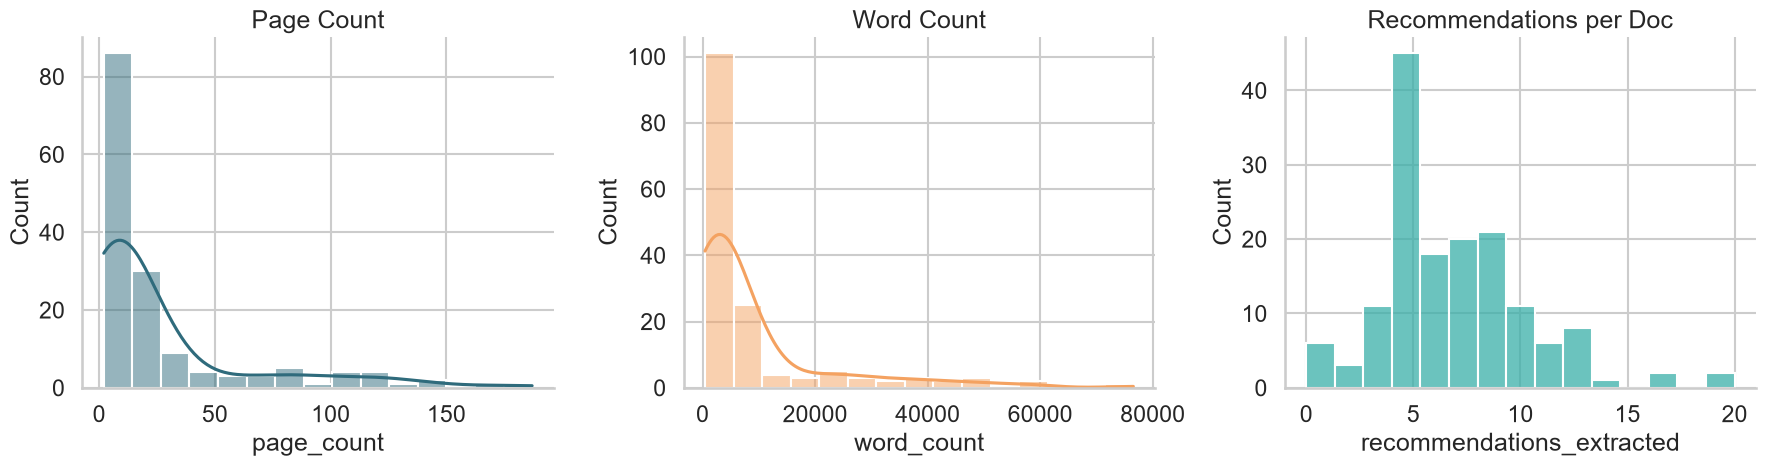

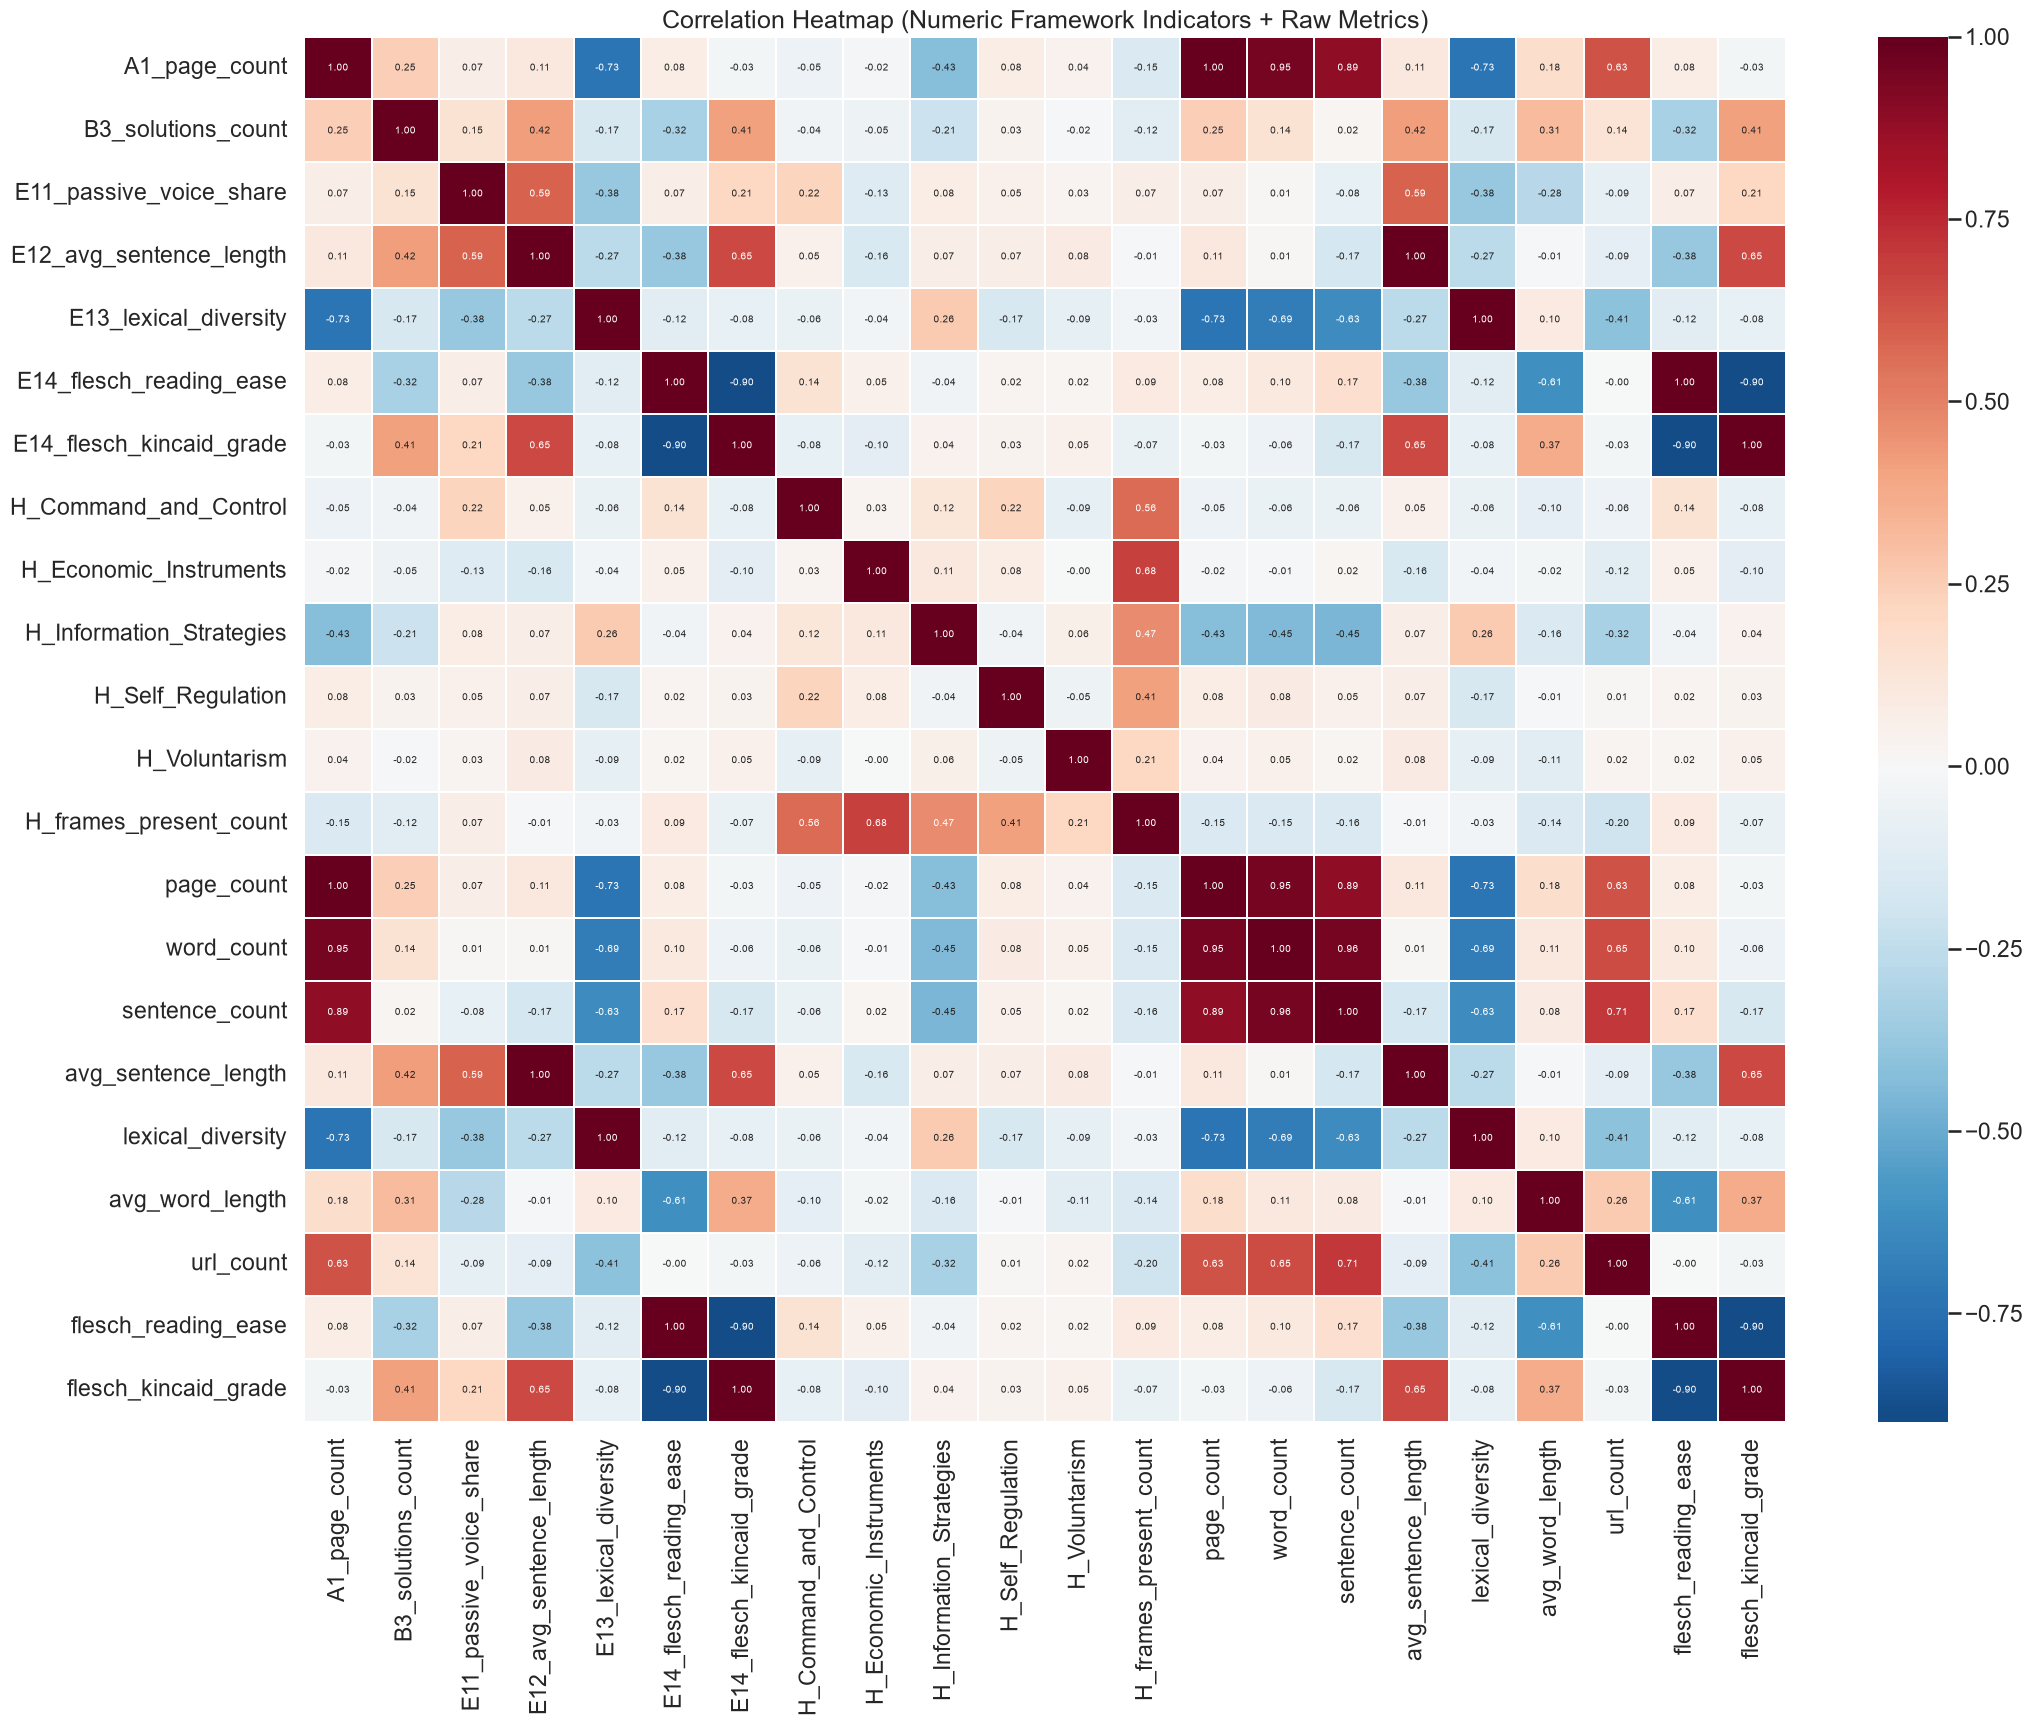

**Top 10 documents by recommendation count:**

,doc_id,page_count,word_count,recommendations_extracted
47,desira_2,101,29712,20
46,desira_1,170,76556,20
103,locomotion_2,8,2013,16
150,terranova_2,11,5253,16
126,resonate_3,82,26603,14
116,pegasus,43,18778,13
40,bloom,24,8350,13
37,biores,29,9154,12
6,basajaun,85,29305,12
39,biw_2,93,10487,12


In [15]:
# ── Dataset-level summary ────────────────────────────────────────────────
qa_summary = pd.DataFrame({
    'dataset': ['documents', 'frames', 'recommendations', 'structural_core'],
    'rows': [len(documents), len(frames), len(recommendations), len(structural_core)],
    'columns': [documents.shape[1], frames.shape[1], recommendations.shape[1], structural_core.shape[1]],
    'missing_cells': [
        documents.isna().sum().sum(), frames.isna().sum().sum(),
        recommendations.isna().sum().sum(), structural_core.isna().sum().sum()
    ],
})
display(qa_summary)

# ── Missingness in documents ────────────────────────────────────────────
display(Markdown('**Top missing columns in documents.csv:**'))
display(documents.isna().sum().sort_values(ascending=False).head(10).rename('missing').to_frame())

# ── Key distributions ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(documents['page_count'], bins=15, kde=True, ax=axes[0], color='#2F6B7C')
axes[0].set_title('Page Count')
sns.histplot(documents['word_count'], bins=15, kde=True, ax=axes[1], color='#F4A261')
axes[1].set_title('Word Count')
if _has_col(documents, 'recommendations_extracted'):
    sns.histplot(documents['recommendations_extracted'], bins=15, ax=axes[2], color='#3AAFA9')
    axes[2].set_title('Recommendations per Doc')
plt.tight_layout()
plt.show()

# ── Correlation heatmap ─────────────────────────────────────────────────
numeric_cols = [c for c in [
    'page_count', 'word_count', 'sentence_count', 'avg_sentence_length',
    'lexical_diversity', 'avg_word_length', 'url_count',
    'flesch_reading_ease', 'flesch_kincaid_grade',
] if c in documents.columns]
# Add framework derived numerics
for c in analysis_df.select_dtypes(include='number').columns:
    if c not in numeric_cols and c != 'doc_id':
        numeric_cols.append(c)

corr_df = analysis_df.merge(documents[['doc_id'] + [c for c in numeric_cols if c in documents.columns]],
                            on='doc_id', how='left', suffixes=('', '_dup'))
# Drop dups
corr_df = corr_df[[c for c in corr_df.columns if not c.endswith('_dup')]]
num = corr_df.select_dtypes(include='number').drop(columns=['doc_id'], errors='ignore')
if num.shape[1] > 2:
    corr = num.corr()
    fig, ax = plt.subplots(figsize=(max(12, num.shape[1]), max(10, num.shape[1] * 0.8)))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, linewidths=0.3, ax=ax,
                annot_kws={'size': 7})
    ax.set_title('Correlation Heatmap (Numeric Framework Indicators + Raw Metrics)')
    plt.tight_layout()
    plt.show()

# ── Documents with extreme values ──────────────────────────────────────
display(Markdown('**Top 10 documents by recommendation count:**'))
display(
    documents[['doc_id', 'page_count', 'word_count', 'recommendations_extracted']]
    .sort_values('recommendations_extracted', ascending=False)
    .head(10)
)